# HW7 - Titanic survival: visualisation

Who survived the Titanic? This notebook explores the passenger list (`titanic.csv`, 1,309 passengers
with class, sex, age, fare, ...) with count plots and survival-rate bars, then fits a small logistic
regression to check how much of the outcome those few variables explain.

From the repository root, execute it headlessly with
`uv run python scripts/run_notebooks.py hw7_titanic_survival/titanic_visualization.ipynb`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

%matplotlib inline

Path('results').mkdir(exist_ok=True)   # figures are also saved here for the README

## Load and prepare

The CSV has one fully empty trailing row, which is dropped. Missing ages are filled with the median and missing embarkation ports with `S` (Southampton, the most common port), as in the original notebook. These filled values are used only for the plots; an untouched copy supplies model features.

In [2]:
df = pd.read_csv('titanic.csv', dtype={'age': np.float64})
df = df.dropna(subset=['survived']).reset_index(drop=True)   # drop the empty trailing row
df[['pclass', 'survived']] = df[['pclass', 'survived']].astype(int)
df.columns = [col.title() for col in df.columns]
model_data = df.copy()   # preserve missing values for fold-local imputation
print(df.shape)

(1309, 14)


In [3]:
df['Embarked'] = df.Embarked.fillna('S')     # (the original filled a new lower-case column instead)
df['Age'] = df.Age.fillna(df.Age.median())

In [4]:
bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90]
df['age_binned'] = pd.cut(df.Age, bins, right=True, include_lowest=False)
# child variable
df['Child'] = (df.Age < 16).astype(int)
surv = df[df.Survived == 1]

## Survivors versus all passengers

White bars: everyone on board; coloured bars: survivors.

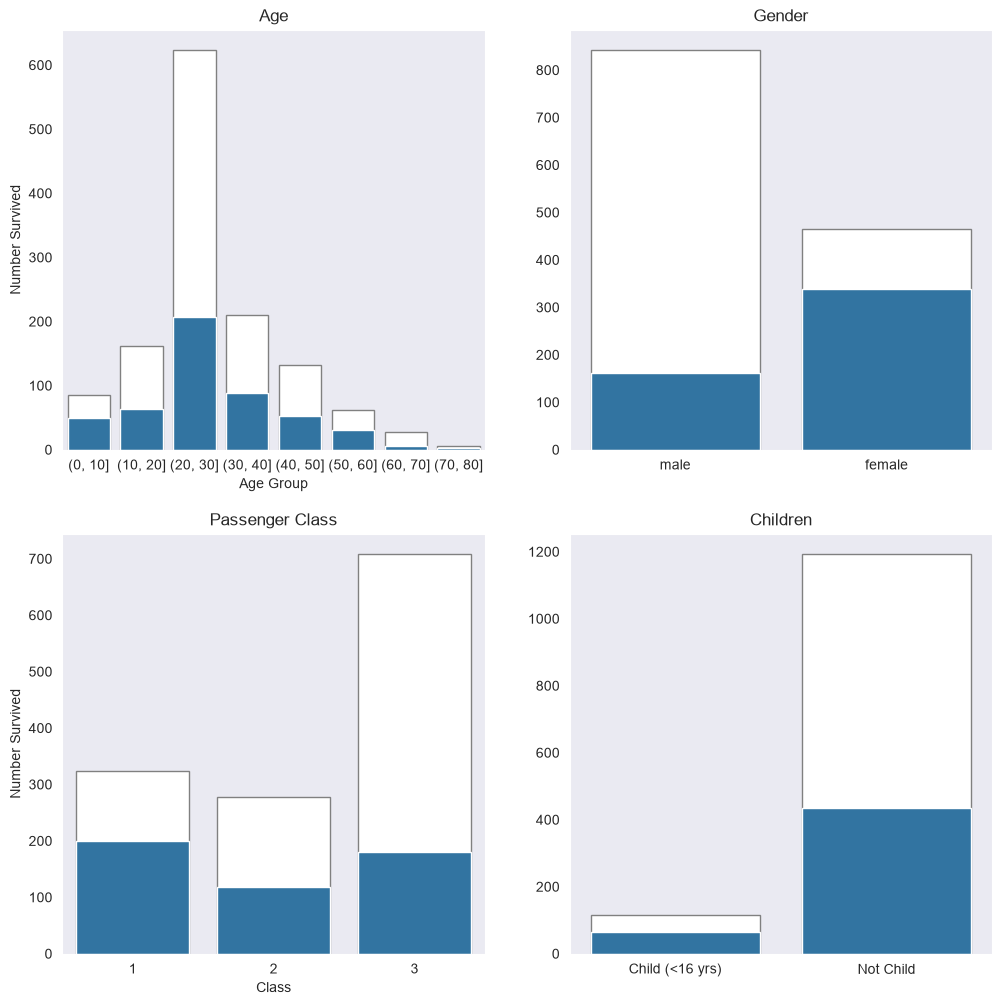

In [5]:
sns.set_style('dark')
fig, ([ax1, ax2], [ax3, ax4]) = plt.subplots(2, 2, figsize=(12, 12))

age_order = list(df.age_binned.cat.categories[:8])   # (0, 10] ... (70, 80]
sns.countplot(x='age_binned', color='white', ax=ax1, data=df, order=age_order, edgecolor='grey')
sns.countplot(x='age_binned', ax=ax1, data=surv, order=age_order)
ax1.set_title('Age')
ax1.set_xlabel('Age Group')
ax1.set_ylabel('Number Survived')

sns.countplot(x='Sex', color='white', ax=ax2, data=df, order=['male', 'female'], edgecolor='grey')
sns.countplot(x='Sex', ax=ax2, data=surv, order=['male', 'female'])
ax2.set_xlabel('')
ax2.set_title('Gender')
ax2.set_ylabel('')

sns.countplot(x='Pclass', color='white', ax=ax3, data=df, order=[1, 2, 3], edgecolor='grey')
sns.countplot(x='Pclass', ax=ax3, data=surv, order=[1, 2, 3])
ax3.set_title('Passenger Class')
ax3.set_ylabel('Number Survived')
ax3.set_xlabel('Class')

sns.countplot(x='Child', color='white', ax=ax4, data=df, order=[1, 0], edgecolor='grey')
sns.countplot(x='Child', ax=ax4, data=surv, order=[1, 0])
ax4.set_xticks([0, 1], ['Child (<16 yrs)', 'Not Child'])
ax4.set_xlabel('')
ax4.set_title('Children')
ax4.set_ylabel('')
fig.savefig('results/survival_counts.png', dpi=100, bbox_inches='tight')
plt.show()

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Pclass      1309 non-null   int64   
 1   Survived    1309 non-null   int64   
 2   Name        1309 non-null   str     
 3   Sex         1309 non-null   str     
 4   Age         1309 non-null   float64 
 5   Sibsp       1309 non-null   float64 
 6   Parch       1309 non-null   float64 
 7   Ticket      1309 non-null   str     
 8   Fare        1308 non-null   float64 
 9   Cabin       295 non-null    str     
 10  Embarked    1309 non-null   str     
 11  Boat        486 non-null    str     
 12  Body        121 non-null    float64 
 13  Home.Dest   745 non-null    str     
 14  age_binned  1309 non-null   category
 15  Child       1309 non-null   int64   
dtypes: category(1), float64(5), int64(3), str(7)
memory usage: 154.9 KB


## Survival rate by class and gender

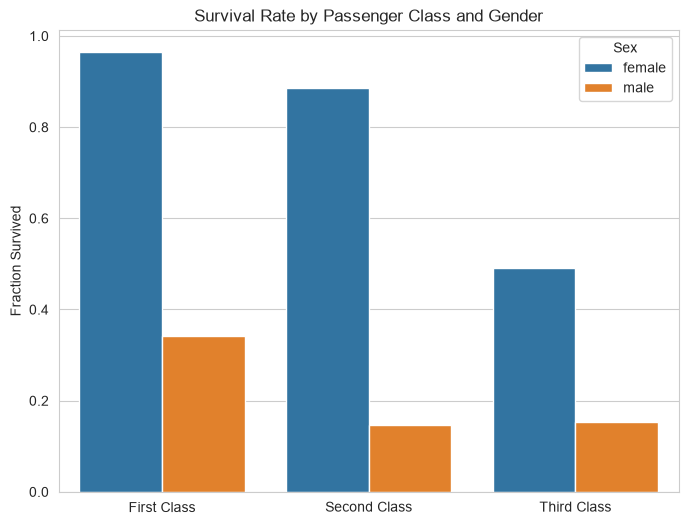

In [7]:
sns.set_style('whitegrid')
fig, axis = plt.subplots(figsize=(8, 6))
sns.barplot(x='Pclass', y='Survived', hue='Sex', data=df, ax=axis, errorbar=None)
axis.set_title('Survival Rate by Passenger Class and Gender')
axis.set_xticks([0, 1, 2], ['First Class', 'Second Class', 'Third Class'])
axis.set_ylabel('Fraction Survived')
axis.set_xlabel('')
fig.savefig('results/survival_rate_by_class_and_sex.png', dpi=100, bbox_inches='tight')
plt.show()

In [8]:
rates = df.groupby(['Pclass', 'Sex']).Survived.agg(rate='mean', passengers='size').round(3)
print(f"Overall survival rate: {df.Survived.mean():.3f}")
rates

Overall survival rate: 0.382


rate  passengers
Pclass Sex                      
1      female  0.965         144
       male    0.341         179
2      female  0.887         106
       male    0.146         171
3      female  0.491         216
       male    0.152         493

## How well do these variables predict survival?

A logistic regression on class, sex, age, family size and fare, scored with stratified 5-fold cross-validation, against a majority-class baseline. Age, child status and fare retain missing values until a median imputer is fitted inside each training fold, followed by scaling. The coefficients below are a descriptive refit on all passengers after evaluation.

In [9]:
features = pd.DataFrame({
    'Pclass': model_data.Pclass,
    'Female': (model_data.Sex == 'female').astype(int),
    'Age': model_data.Age,
    'Child': (model_data.Age < 16).astype(float).where(model_data.Age.notna()),
    'FamilySize': model_data.Sibsp + model_data.Parch,
    'Fare': model_data.Fare,
})
target = df.Survived.astype(int)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

baseline = cross_val_score(DummyClassifier(strategy='most_frequent'), features, target, cv=folds)
model = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000))
scores = cross_val_score(model, features, target, cv=folds)
print(f"majority-class baseline accuracy: {baseline.mean():.3f}")
print(f"logistic regression accuracy:     {scores.mean():.3f} +/- {scores.std():.3f}")

coefs = model.fit(features, target)[-1].coef_[0]
pd.Series(coefs, index=features.columns).sort_values().round(2)

majority-class baseline accuracy: 0.618
logistic regression accuracy:     0.792 +/- 0.016


Pclass       -0.77
FamilySize   -0.42
Age          -0.26
Fare          0.16
Child         0.35
Female        1.26
dtype: float64